  stn_code       sampling_date           state   location agency  \
0    150.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
1    151.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
2    152.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
3    150.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   
4    151.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   

                                 type  so2   no2  rspm  spm  \
0  Residential, Rural and other Areas  4.8  17.4   NaN  NaN   
1                     Industrial Area  3.1   7.0   NaN  NaN   
2  Residential, Rural and other Areas  6.2  28.5   NaN  NaN   
3  Residential, Rural and other Areas  6.3  14.7   NaN  NaN   
4                     Industrial Area  4.7   7.5   NaN  NaN   

  location_monitoring_station  pm2_5        date  
0                         NaN    NaN  1990-02-01  
1                         NaN    NaN  1990-02-01  
2                         NaN    NaN  1990-02-01  
3       

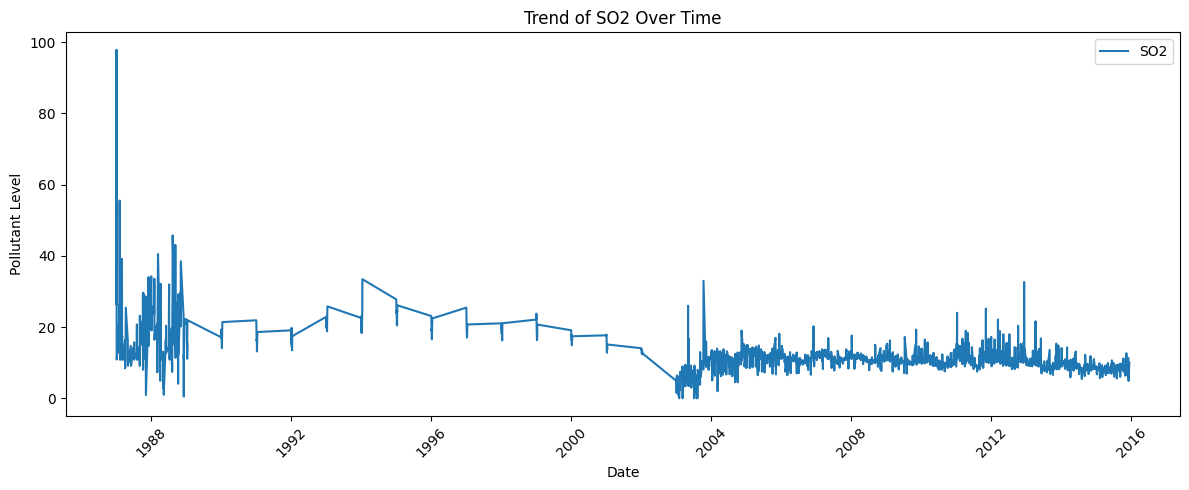

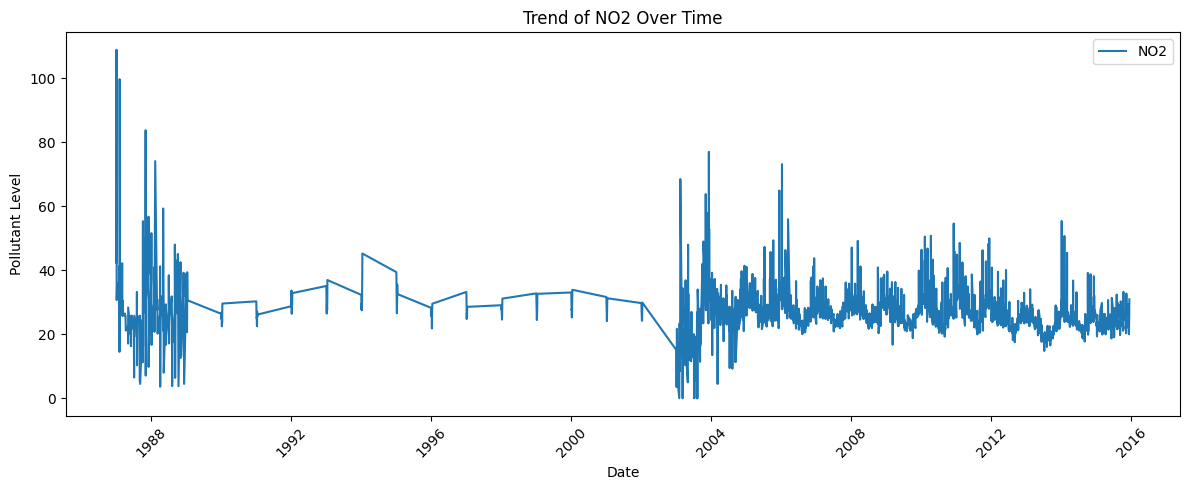

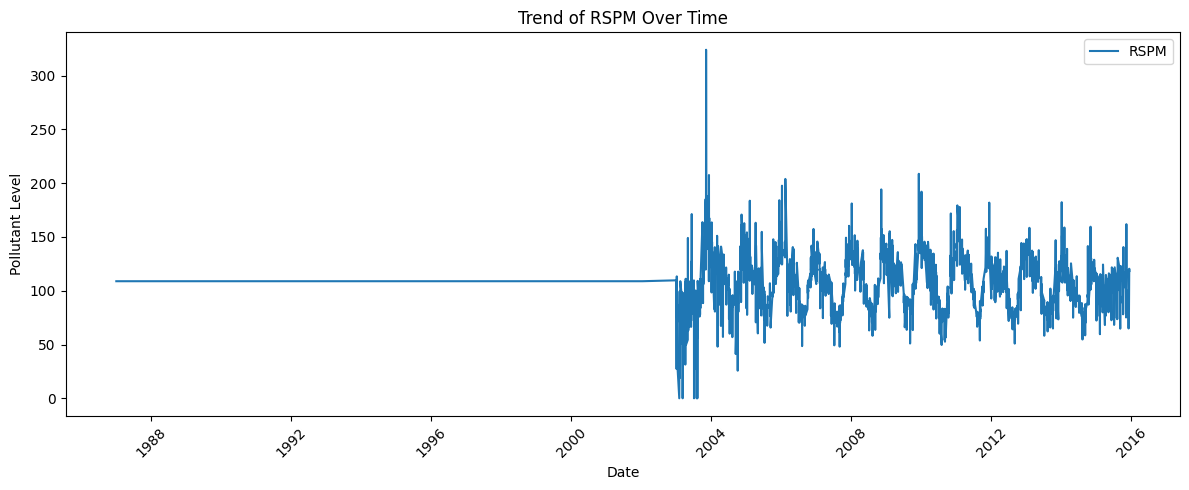

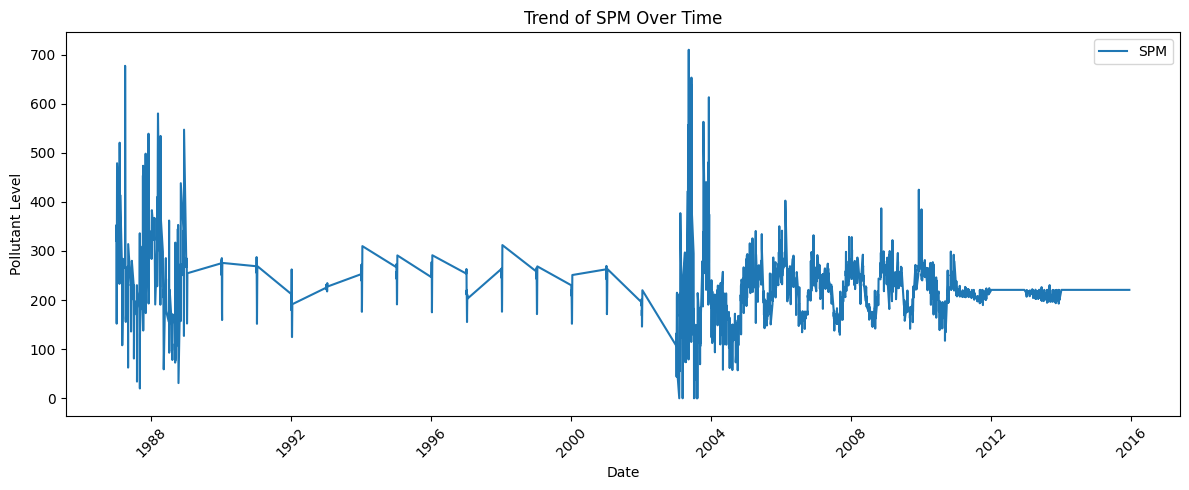

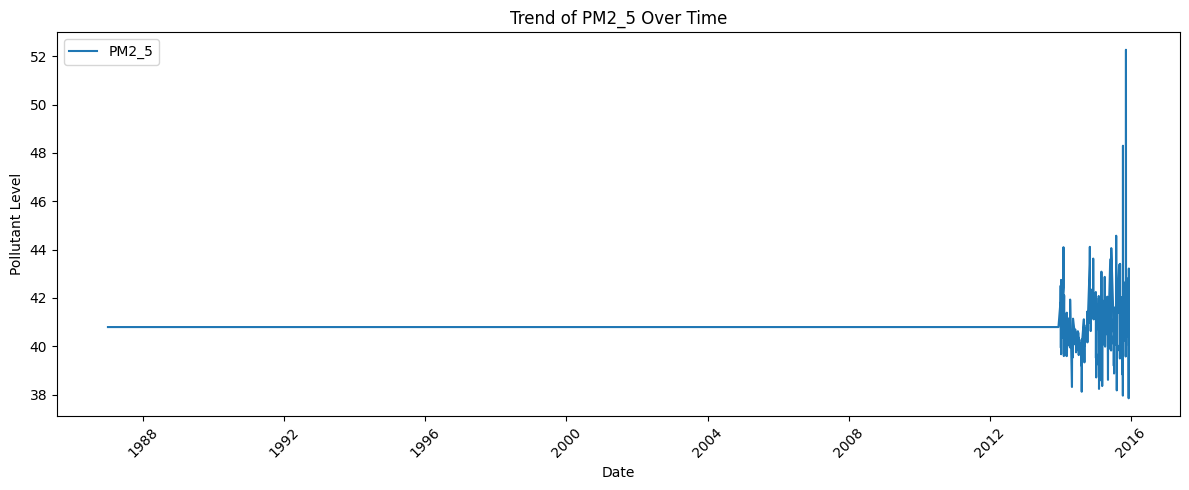

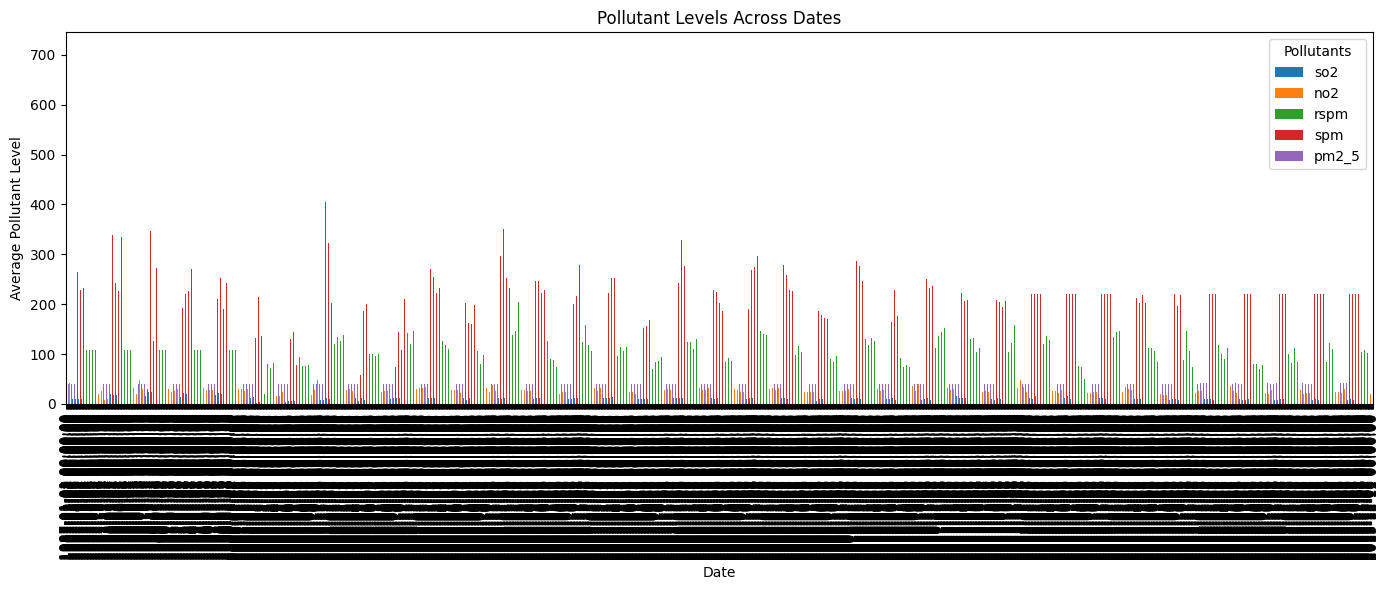

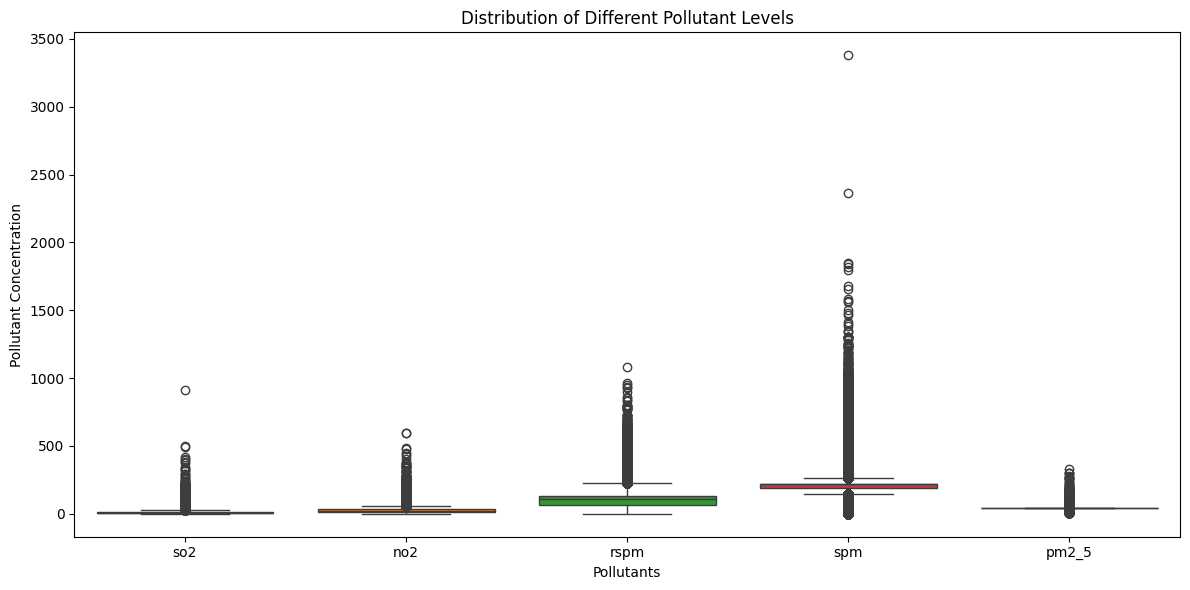

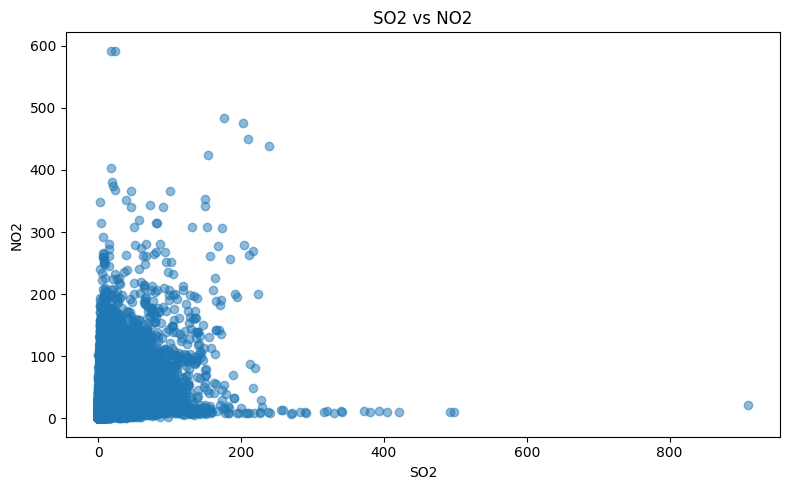

Air Quality Data Visualization Completed.


In [2]:

# Experiment: Data Visualization using Matplotlib
# Analyzing Air Quality Trends

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# 1. Import dataset
data = pd.read_csv("data.csv", encoding="cp1252")

# 2. Explore dataset
print(data.head())
print(data.tail())
print(data.info())
print(data.describe())

# Standardize column names
data.columns = data.columns.str.strip().str.lower()

# 3. Identify relevant variables
# date = Date of measurement
# so2, no2, rspm, spm, pm2_5 = Pollutant levels

# Convert date into datetime format
data['date'] = pd.to_datetime(data['date'], errors='coerce', dayfirst=True)

# Identify available pollutant columns
VALUE_COLS = ['so2', 'no2', 'rspm', 'spm', 'pm2_5', 'pm10', 'co']
VALUE_COLS = [col for col in VALUE_COLS if col in data.columns]

# Convert pollutant columns into numeric format
for col in VALUE_COLS:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Fill missing pollutant values with mean
for col in VALUE_COLS:
    data[col] = data[col].fillna(data[col].mean())

# Check missing values
print("Missing Values:")
print(data.isnull().sum())

# Identify AQI column, if available
AQI_COL = next(
    (col for col in ['aqi', 'air_quality_index'] if col in data.columns),
    None
)

# Sort data by date
data = data.dropna(subset=['date'])
data = data.sort_values('date')

# Calculate average pollutant levels by date
daily_data = data.groupby('date')[VALUE_COLS].mean()

# 4. Line plot for overall AQI trend
if AQI_COL:
    data[AQI_COL] = pd.to_numeric(data[AQI_COL], errors='coerce')
    aqi_trend = data.groupby('date')[AQI_COL].mean()

    plt.figure(figsize=(12, 5))
    plt.plot(aqi_trend.index, aqi_trend.values, label='AQI')
    plt.title("Overall AQI Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("AQI")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("AQI column is not available in this dataset.")

# 5. Individual pollutant trends over time
for col in VALUE_COLS:
    plt.figure(figsize=(12, 5))
    plt.plot(daily_data.index, daily_data[col], label=col.upper())
    plt.title("Trend of " + col.upper() + " Over Time")
    plt.xlabel("Date")
    plt.ylabel("Pollutant Level")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 6. Bar plot to compare AQI across dates
if AQI_COL:
    aqi_daily = data.groupby('date')[AQI_COL].mean()

    plt.figure(figsize=(12, 5))
    plt.bar(aqi_daily.index, aqi_daily.values)
    plt.title("AQI Comparison Across Dates")
    plt.xlabel("Date")
    plt.ylabel("AQI")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    # Compare available pollutant levels across dates
    daily_data.plot(kind='bar', figsize=(14, 6))
    plt.title("Pollutant Levels Across Dates")
    plt.xlabel("Date")
    plt.ylabel("Average Pollutant Level")
    plt.legend(title="Pollutants")
    plt.tight_layout()
    plt.show()

# 7. Box plot to analyze pollutant distributions
plt.figure(figsize=(12, 6))
sns.boxplot(data=data[VALUE_COLS])
plt.title("Distribution of Different Pollutant Levels")
plt.xlabel("Pollutants")
plt.ylabel("Pollutant Concentration")
plt.tight_layout()
plt.show()

# 8. Scatter plots to explore relationships
if AQI_COL:
    for col in VALUE_COLS:
        plt.figure(figsize=(7, 5))
        plt.scatter(data[col], data[AQI_COL], alpha=0.5)
        plt.title("AQI vs " + col.upper())
        plt.xlabel(col.upper())
        plt.ylabel("AQI")
        plt.tight_layout()
        plt.show()
else:
    # Compare available pollutant variables
    if len(VALUE_COLS) >= 2:
        plt.figure(figsize=(8, 5))
        plt.scatter(data[VALUE_COLS[0]], data[VALUE_COLS[1]], alpha=0.5)
        plt.title(VALUE_COLS[0].upper() + " vs " + VALUE_COLS[1].upper())
        plt.xlabel(VALUE_COLS[0].upper())
        plt.ylabel(VALUE_COLS[1].upper())
        plt.tight_layout()
        plt.show()

# 9. Visualization customization
# Titles, labels, legends, colors and figure sizes
# are included in all the above plots.

print("Air Quality Data Visualization Completed.")
